---

<table style="width:100%">
  <tr>
    <th>
        <div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> Конспект лекцій з предмету: </p>
<p style="text-align: center;"><b><h2>"Схемотехніка радіотехнічних пристроїв. Частина 3"</h2></b></p>
<p style="text-align: center;"><b><h3>Тема 13. Мультивібратори</h3></b></p>
<p style="text-align: center;"> Національний університет "Чернігівська політехніка"</p>
<hr/>
<p style="text-align: center;"><b>Питання теми:</b></p>
<ul style="text-align: left;">
  <li>3.13. Мультивібратор на операційному підсилювачі: основні розрахункові співвідношення та діаграми роботи</li>
  <li>3.14. Способи зміни шпаруватості імпульсів у мультивібраторах на операційному підсилювачі</li>
  <li>3.15. Мультивібратор на логічних мікросхемах: основні розрахункові співвідношення та діаграми роботи</li>
  <li>3.16. Мультивібратори на логічних елементах з одним частотозадавальним колом</li>
  <li>3.17. Мультивібратори на інтегральному таймері: основні розрахункові співвідношення та діаграми роботи</li>
</ul>
</div>
    </th>
    <th>
<div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> <b>Викладач:</b> </p>
<p style="text-align: center;"> Доктор філософії</p>
<p style="text-align: center;"> Пахалюк Богдан Петрович</p>
<hr/>
<p style="text-align: center; font-size: 0.9em;">Тема 13 з 14</p>
</div>
    </th>
  </tr>
</table>

---


---

<p style="text-align: center;"><b>Зміст</b></p>

* [Мультивібратор на ОП](#opamp-astable)
    * [🔬 Інтерактивно: мультивібратор і функціональний генератор на μA741 (PySpice)](#astable-interactive)
* [Зміна шпаруватості імпульсів мультивібратора на ОП](#duty)
    * [🔬 Інтерактивно: регулювання шпаруватості потенціометром (PySpice)](#duty-interactive)
* [Мультивібратори на логічних мікросхемах](#gate-astable)
* [Мультивібратори на логічних елементах з одним частотозадавальним колом](#one-rc)
    * [🔬 Інтерактивно: мультивібратор на двох КМОН-інверторах (PySpice)](#cmos-interactive)
* [Мультивібратор на інтегральному таймері 555](#timer-555)
    * [🔬 Інтерактивно: мультивібратор на таймері 555 (PySpice, модель біполярного 555)](#ne555-interactive)
* [📌 Підсумок теми](#topic-summary)
* [📚 Рекомендована література та ресурси](#references)

> 💡 Код демонстрацій та інтерактивних графіків **згорнуто**, щоб не відволікати від матеріалу. Щоб переглянути його, натисніть на «⋯» (або на смужку ліворуч від комірки). Для роботи інтерактивних елементів виконайте всі комірки: *Run → Run All Cells*.

---

**Підключення бібліотек.** NumPy/SciPy/Matplotlib — чисельні розрахунки та графіки, SymPy — символьні обчислення, ipywidgets — інтерактивні повзунки, PySpice + ngspice — моделювання схем (ОП μA741, таймер 555 та транзистори описано SPICE-моделями з теки `spice/`), schemdraw — побудова схем з умовними позначеннями за ДСТУ. Цю комірку потрібно виконати першою; у Google Colab вона спершу встановлює ngspice і бібліотеки (близько хвилини).

In [1]:
import sys, os
if 'google.colab' in sys.modules and not os.path.exists('/usr/lib/x86_64-linux-gnu/libngspice.so'):   # Google Colab: ngspice та бібліотеки (~1 хв)
    !apt-get -qq install -y ngspice libngspice0-dev > /dev/null
    %pip install -q PySpice==1.5 schemdraw==0.23 engineering_notation==0.13.3

# SPICE-моделі компонентів (ОП μA741, таймер 555, діоди, транзистори) лежать у теці spice/;
# якщо зошит відкрито окремо (напр. у Colab), завантажуємо їх із репозиторію
SPICE_DIR = 'spice'
if not os.path.isdir(SPICE_DIR):
    import urllib.request
    os.makedirs(SPICE_DIR, exist_ok=True)
    _repo = 'https://raw.githubusercontent.com/vim4all/Lectures_Schematics_of_radio_technical-devices_in_Ukrainian/main/spice/'
    for _f in ['uA741.lib', 'BIP-555.lib', '1N4007.mod', '2n2222a.lib', '2n3904.lib']:
        urllib.request.urlretrieve(_repo + _f, os.path.join(SPICE_DIR, _f))
def spice_model(name):
    return os.path.abspath(os.path.join(SPICE_DIR, name))

import warnings
warnings.filterwarnings('ignore', message='Unable to import Axes3D')
import sympy as smp
from sympy import symbols, Matrix, simplify, factor, solve, Eq, latex
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
from ipywidgets import interact, interactive, fixed, HBox, VBox, Output
import ipywidgets as widgets
from IPython.display import display, HTML, Markdown
%matplotlib inline
try:                                     # схеми й графіки — лише PNG (менший розмір зошитів)
    get_ipython().display_formatter.formatters['image/svg+xml'].enabled = False
except Exception:
    pass

import math
from engineering_notation import EngNumber

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging(logging_level='ERROR')
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

# ngspice ≥ 41 пише в stderr інформаційні повідомлення (напр. "Using SPARSE 1.3 as Direct Linear Solver"),
# які PySpice 1.5 вважає помилкою симуляції. Сприймаємо як помилку лише рядки, що містять "error".
from PySpice.Spice.NgSpice import Shared as _ngspice_shared
_orig_send_char = _ngspice_shared.NgSpiceShared._send_char
def _send_char(message_c, ngspice_id, user_data):
    message = _ngspice_shared.ffi_string_utf8(message_c)
    prefix, _, content = message.partition(' ')
    if prefix == 'stderr' and 'error' not in content.lower() and 'init file' not in content:
        self = _ngspice_shared.ffi.from_handle(user_data)
        self._stderr.append(content)
        return self.send_char(message, ngspice_id)
    return _orig_send_char(message_c, ngspice_id, user_data)
_ngspice_shared.NgSpiceShared._send_char = staticmethod(_send_char)

def opamp_circuit(title, supply=15):
    """Схема з ОП μA741 і двополярним живленням ±supply (вузли vcc, vee)."""
    c = Circuit(title)
    c.include(spice_model('uA741.lib'))
    c.V('cc', 'vcc', c.gnd, supply)
    c.V('ee', 'vee', c.gnd, -supply)
    return c

def add_opamp(c, name, plus, minus, out):
    """ОП μA741: X<name> (+) (−) Vcc Vee вихід."""
    c.X(name, 'UA741', plus, minus, 'vcc', 'vee', out)

def tran(c, step, stop, start=0, **kw):
    """Перехідний аналіз: повертає (t, словник напруг вузлів у вигляді numpy-масивів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).transient(step_time=step, end_time=stop, start_time=start, **kw)
    return np.array(a.time), {str(k): np.array(v) for k, v in a.nodes.items()}

def ac(c, f_start=1, f_stop=10e6, points=40):
    """AC-аналіз: повертає (f, словник комплексних напруг вузлів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).ac(start_frequency=f_start, stop_frequency=f_stop,
                                                                 number_of_points=points, variation='dec')
    return np.array(a.frequency), {str(k): np.array(v) for k, v in a.nodes.items()}

def db(x):
    return 20 * np.log10(np.maximum(np.abs(x), 1e-12))

try:
    import schemdraw
    import schemdraw.elements as elm
    SCHEMDRAW_AVAILABLE = True
except ImportError:
    SCHEMDRAW_AVAILABLE = False
    print('schemdraw не встановлено (pip install schemdraw)')

plt.rcParams.update({
    'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.3,
    'axes.labelsize': 12, 'axes.titlesize': 13, 'lines.linewidth': 2,
    'font.size': 11,
})

if SCHEMDRAW_AVAILABLE:
    # Умовні позначення за ДСТУ/IEC: резистор — прямокутник, джерело ЕРС — коло зі стрілкою,
    # операційний підсилювач — прямокутник із символом ▷∞, логічні елементи — прямокутники з «&», «1»
    from schemdraw.segments import Segment, SegmentCircle, SegmentText
    elm.style(elm.STYLE_IEC)
    schemdraw.use('matplotlib')
    import schemdraw.backends.svgtext as _svgtext       # оцінювач розміру тексту schemdraw не сприймає символ «&»
    _orig_text_size = _svgtext.text_approx_size
    _svgtext.text_approx_size = lambda text, *a, **k: _orig_text_size(text.replace('&', '8'), *a, **k)

    class EMF(elm.Source):
        """Джерело ЕРС: стрілка всередині кола вказує напрямок дії ЕРС."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.2, 0), (.8, 0)], arrow='->', arrowwidth=.16, arrowlength=.25))

    class CurrentSource(elm.Source):
        """Джерело струму: подвійна стрілка вказує напрямок струму."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.15, 0), (.85, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))
            self.segments.append(Segment([(.15, 0), (.62, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))

    class OpAmp(elm.Element):
        """Операційний підсилювач за ДСТУ: прямокутник із символом ▷∞.
        Інвертувальний вхід in1 (з кружечком інверсії) — угорі, неінвертувальний in2 — унизу;
        swap=True міняє входи місцями (неінвертувальний — угорі). Виводи: in1, in2, out, vd (живлення +), vs (живлення −)."""
        def __init__(self, swap=False, signs=True, **kwargs):
            super().__init__(**kwargs)
            w, h, lead, r = 2.0, 2.6, 0.6, 0.12
            yi, yn = (0.65, -0.65) if not swap else (-0.65, 0.65)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(Segment([(0.55, h/2 - 0.3), (0.55, h/2 - 0.8), (0.95, h/2 - 0.55), (0.55, h/2 - 0.3)]))
            self.segments.append(SegmentText((1.35, h/2 - 0.55), '∞', fontsize=14))
            self.segments.append(SegmentCircle((-r, yi), r))
            self.segments.append(Segment([(-lead, yi), (-2*r, yi)]))
            self.segments.append(Segment([(-lead, yn), (0, yn)]))
            self.segments.append(Segment([(w, 0), (w + lead, 0)]))
            if signs:
                self.segments.append(SegmentText((0.25, yi), '−', fontsize=12))
                self.segments.append(SegmentText((0.25, yn), '+', fontsize=12))
            self.anchors.update({'in1': (-lead, yi), 'in2': (-lead, yn), 'out': (w + lead, 0),
                                 'vd': (w/2, h/2), 'vs': (w/2, -h/2), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

    class Gate(elm.Element):
        """Логічний елемент за ДСТУ: прямокутник із функцією ('&', '1', '=1') і кружечком інверсії на виході.
        Виводи: in1 … inN (зверху вниз), out."""
        def __init__(self, func='&', inputs=2, inv=True, **kwargs):
            super().__init__(**kwargs)
            w, lead, r = 1.4, 0.5, 0.12
            h = max(1.4, 0.8 * inputs)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(SegmentText((w/2, h/2 - 0.3), func, fontsize=13))
            ys = [0.0] if inputs == 1 else list(np.linspace(h/2 - 0.4, -h/2 + 0.4, inputs))
            for k, y in enumerate(ys):
                self.segments.append(Segment([(-lead, y), (0, y)]))
                self.anchors[f'in{k+1}'] = (-lead, y)
            x0 = w
            if inv:
                self.segments.append(SegmentCircle((w + r, 0), r))
                x0 = w + 2*r
            self.segments.append(Segment([(x0, 0), (w + lead, 0)]))
            self.anchors.update({'out': (w + lead, 0), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

---

## Мультивібратор на ОП <a class="anchor" id="opamp-astable"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 3.13</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати принцип дії мультивібратора як тригера Шмітта з RC-колом
> - Виводити формулу періоду коливань
> - Будувати часові діаграми напруги на конденсаторі і на виході

</div>

**Мультивібратор** — релаксаційний генератор прямокутних імпульсів. Найпростіший мультивібратор на ОП — **інвертувальний тригер Шмітта** (тема 9), вихід якого через резистор $R$ перезаряджає конденсатор $C$ на інвертувальному вході.

**Принцип дії.** Нехай вихід $U_{вих} = +U_{нас}$, тоді на неінвертувальному вході — поріг $U_+ = \gamma U_{нас}$, де $\gamma = \dfrac{R_1}{R_1 + R_2}$. Конденсатор заряджається через $R$ з прагненням до $+U_{нас}$. Коли $u_C$ досягає $\gamma U_{нас}$, ОП перемикається: $U_{вих} = -U_{нас}$, поріг стрибком змінюється на $-\gamma U_{нас}$, і конденсатор перезаряджається у зворотному напрямку до $-\gamma U_{нас}$ — цикл повторюється. Напруга на конденсаторі — відрізки експонент між порогами $\pm\gamma U_{нас}$, на виході — меандр.

**Період.** Перезаряд від $-\gamma U$ до $+\gamma U$ з прагненням до $+U$:
$$t_1 = t_2 = RC\ln\frac{1 + \gamma}{1 - \gamma} = RC\ln\left(1 + \frac{2R_1}{R_2}\right),\qquad T = 2RC\ln\left(1 + \frac{2R_1}{R_2}\right).$$
При $R_1 = R_2$: $T = 2RC\ln3 \approx 2{,}2RC$; при $R_2 = 1{,}16R_1$: $T = 2RC$.

**Обмеження:** швидкість наростання ОП обмежує фронти (для μA741 — десятки мікросекунд на перемикання), тому для частот вище кількох кілогерц використовують компаратори; вихідні рівні залежать від напруги живлення (стабілізують стабілітронами на виході).

**Генератор трикутних і прямокутних імпульсів (функціональний генератор).** Неінвертувальний тригер Шмітта + інтегратор у петлі: інтегратор формує **лінійно** змінну напругу (трикутник) між порогами тригера, тригер — меандр:
$$U_{трик.max} = \frac{R_1}{R_2}U_{нас},\qquad T = 4RC\frac{R_1}{R_2}.$$

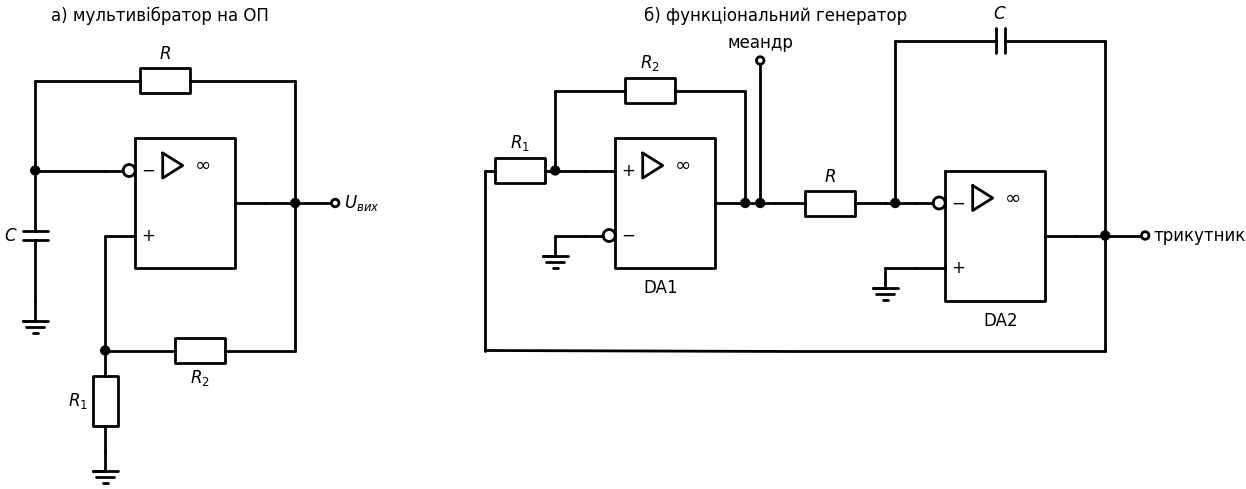

In [2]:
# а) мультивібратор на ОП; б) функціональний генератор: тригер Шмітта + інтегратор
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += elm.Label().at((3.0, 5.0)).label('а) мультивібратор на ОП')
        d += (o := OpAmp().at((2.0, 2)).anchor('in1'))
        d += W((0.6, 2), (2.0, 2)); d += elm.Dot().at((0.6, 2))
        d += elm.Capacitor().at((0.6, 2)).to((0.6, -0.6)).label('$C$', loc='top'); d += elm.Ground().at((0.6, -0.6))
        d += W((0.6, 2), (0.6, 3.8)); d += elm.Resistor().at((0.6, 3.8)).to((5.8, 3.8)).label('$R$'); d += W((5.8, 3.8), (5.8, o.out[1]))
        d += elm.Dot().at((5.8, o.out[1])); d += W(o.out, (6.6, o.out[1])); d += elm.Dot(open=True).at((6.6, o.out[1])).label('$U_{вих}$', loc='right')
        xp = o.in2[0]                                        # абсциса виводу «+»
        d += W(o.in2, (xp, -1.6)); d += elm.Dot().at((xp, -1.6))
        d += elm.Resistor().at((xp, -1.6)).to((xp, -3.6)).label('$R_1$', loc='top'); d += elm.Ground().at((xp, -3.6))
        d += elm.Resistor().at((xp, -1.6)).to((5.8, -1.6)).label('$R_2$', loc='bottom'); d += W((5.8, -1.6), (5.8, o.out[1]))
        # б) функціональний генератор
        ox = 10
        d += elm.Label().at((ox + 5.5, 5.0)).label('б) функціональний генератор')
        d += (s := OpAmp(swap=True).at((ox + 1.6, 2)).anchor('in2')); d += elm.Label().at((s.center[0], s.center[1] - 1.8)).label('DA1')
        d += W(s.in1, (ox + 1.0, s.in1[1])); d += elm.Ground().at((ox + 1.0, s.in1[1]))
        d += W((ox + 1.0, 2), (ox + 1.6, 2)); d += elm.Dot().at((ox + 1.0, 2))
        d += W((ox + 1.0, 2), (ox + 1.0, 3.6)); d += elm.Resistor().at((ox + 1.0, 3.6)).to((ox + 4.8, 3.6)).label('$R_2$'); d += W((ox + 4.8, 3.6), (ox + 4.8, s.out[1]))
        d += elm.Dot().at((ox + 4.8, s.out[1])); d += W(s.out, (ox + 5.4, s.out[1]))
        d += elm.Resistor().at((ox + 5.4, s.out[1])).to((ox + 7.6, s.out[1])).label('$R$')
        d += (i := OpAmp().at((ox + 8.2, s.out[1])).anchor('in1')); d += elm.Label().at((i.center[0], i.center[1] - 1.8)).label('DA2')
        d += W((ox + 7.6, s.out[1]), (ox + 8.2, s.out[1])); d += elm.Dot().at((ox + 7.8, s.out[1]))
        d += W((ox + 7.8, s.out[1]), (ox + 7.8, 4.6)); d += elm.Capacitor().at((ox + 7.8, 4.6)).to((ox + 12.0, 4.6)).label('$C$'); d += W((ox + 12.0, 4.6), (ox + 12.0, i.out[1]))
        d += W(i.in2, (ox + 7.6, i.in2[1]))
        d += elm.Ground().at((ox + 7.6, i.in2[1]))
        d += elm.Dot().at((ox + 12.0, i.out[1])); d += W(i.out, (ox + 12.8, i.out[1])); d += elm.Dot(open=True).at((ox + 12.8, i.out[1])).label('трикутник', loc='right')
        d += W((ox + 12.0, i.out[1]), (ox + 12.0, -1.6)); d += W((ox + 12.0, -1.6), (ox - 0.4, -1.6)); d += W((ox - 0.4, -1.6), (ox - 0.4, 2))
        d += elm.Resistor().at((ox - 0.4, 2)).to((ox + 1.0, 2)).label('$R_1$')
        d += elm.Dot().at((ox + 5.1, s.out[1])); d += W((ox + 5.1, s.out[1]), (ox + 5.1, 4.2)); d += elm.Dot(open=True).at((ox + 5.1, 4.2)).label('меандр', loc='top')

---
### 🔬 Інтерактивно: мультивібратор і функціональний генератор на μA741 (PySpice) <a class="anchor" id="astable-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Ліворуч — мультивібратор (тригер Шмітта + RC): напруга на конденсаторі перезаряджається між порогами $\pm\gamma U_{нас}$. Праворуч — функціональний генератор (тригер Шмітта + інтегратор) з лінійним трикутником. Змінюйте $R_2/R_1$ і $C$: під графіками — порівняння періоду з формулами. На малих $C$ помітно, як швидкість наростання μA741 подовжує період.

</div>

In [3]:
# Мультивібратор на ОП і генератор трикутних/прямокутних імпульсів (μA741)
def astable(R2_k=10.0, C_nF=100.0):
    R, R1, C = 10e3, 10e3, C_nF * 1e-9
    T1 = 2 * R * C * np.log(1 + 2 * R1 / (R2_k * 1e3))
    c = opamp_circuit('astable')
    c.R('f', 'out', 'm', R); c.C(1, 'm', c.gnd, C); c.R(1, 'p', c.gnd, R1); c.R(2, 'out', 'p', R2_k * 1e3)
    add_opamp(c, 1, 'p', 'm', 'out')
    t, v = tran(c, T1 / 1000, 5 * T1)
    # функціональний генератор: R1 = 10 кОм (від трикутника), R2 — від меандру; інтегратор R = 10 кОм, C
    R2f = max(R2_k, 10.5) * 1e3
    T2 = 4 * R * C * R1 / R2f
    g = opamp_circuit('function generator')
    g.R(1, 'tri', 'p', R1); g.R(2, 'sq', 'p', R2f); add_opamp(g, 1, 'p', c.gnd, 'sq')
    g.R('i', 'sq', 'm', R); g.C('i', 'm', 'tri', C); add_opamp(g, 2, c.gnd, 'm', 'tri')
    t2, v2 = tran(g, T2 / 1000, 5 * T2)
    def period(t, u):
        e = t[1:][(u[1:] > 0) & (u[:-1] <= 0)]
        return np.diff(e)[-2:].mean() if len(e) > 3 else np.nan
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4))
    a1.plot(t * 1e3, v['out'], color='#F44336', label='$u_{вих}$'); a1.plot(t * 1e3, v['m'], color='#2196F3', label='$u_C$')
    gam = R1 / (R1 + R2_k * 1e3)
    a1.axhline(13 * gam, color='k', ls=':', lw=1); a1.axhline(-13 * gam, color='k', ls=':', lw=1)
    a1.set_xlabel('t, мс'); a1.set_ylabel('В'); a1.legend(loc='upper right', fontsize=9)
    a1.set_title(f'Мультивібратор: T = {period(t, v["out"])*1e3:.3f} мс (формула {T1*1e3:.3f})')
    a2.plot(t2 * 1e3, v2['sq'], color='#F44336', label='меандр'); a2.plot(t2 * 1e3, v2['tri'], color='#4CAF50', label='трикутник')
    a2.set_xlabel('t, мс'); a2.legend(loc='upper right', fontsize=9)
    a2.set_title(f'Функціональний генератор: T = {period(t2, v2["sq"])*1e3:.3f} мс (формула {T2*1e3:.3f})')
    plt.tight_layout(); plt.show()

interact(astable,
         R2_k=widgets.FloatSlider(min=5, max=50, step=0.5, value=10, description='R2 (кОм)'),
         C_nF=widgets.FloatLogSlider(base=10, min=0, max=3, step=0.1, value=100, description='C (нФ)'));

interactive(children=(FloatSlider(value=10.0, description='R2 (кОм)', max=50.0, min=5.0, step=0.5), FloatLogSl…

---

## Зміна шпаруватості імпульсів мультивібратора на ОП <a class="anchor" id="duty"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 3.14</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати поняття шпаруватості і коефіцієнта заповнення
> - Знати способи незалежного регулювання тривалості імпульсу і паузи
> - Розраховувати мультивібратор із заданою шпаруватістю

</div>

**Шпаруватість** $Q = T/t_і$ — відношення періоду до тривалості імпульсу; обернена величина — **коефіцієнт заповнення** $D = t_і/T$. Симетричний мультивібратор (меандр) має $Q = 2$, $D = 50\%$.

**Способи зміни шпаруватості:**
1. **Різні опори заряду і розряду конденсатора.** Замість одного $R$ — два резистори з діодами: VD1 відкритий при $U_{вих} > 0$ (заряд через $R'$), VD2 — при $U_{вих} < 0$ (розряд через $R''$):
$$t_і = R'C\ln\left(1 + \frac{2R_1}{R_2}\right),\qquad t_п = R''C\ln\left(1 + \frac{2R_1}{R_2}\right),\qquad D = \frac{R'}{R' + R''}.$$
З потенціометром між діодами ($R' + R'' = \text{const}$) шпаруватість змінюється **без зміни періоду**. (Строго, слід враховувати падіння напруги на діоді.)
2. **Несиметричні пороги** — опорна напруга $U_{оп}$ на нижньому кінці $R_1$ (або на неінвертувальному вході) зсуває петлю гістерезису; час заряду до вищого порогу і розряду до нижчого стає різним.
3. **Несиметричні рівні виходу** (різні стабілітрони в колі обмеження) — різні «рушійні» напруги при заряді і розряді.
4. **Функціональний генератор + компаратор:** трикутник порівнюють з регульованою постійною напругою — це **широтно-імпульсний модулятор (ШІМ)**: $D$ лінійно залежить від напруги керування, частота стала.

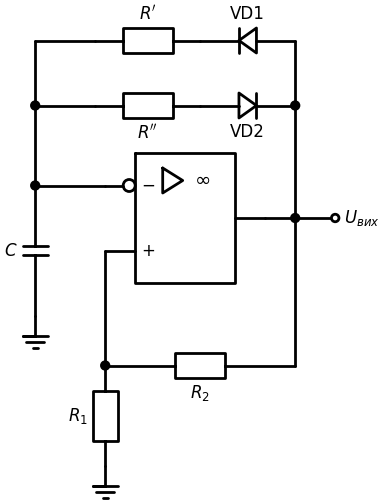

In [4]:
# Мультивібратор на ОП з регульованою шпаруватістю (різні кола заряду і розряду)
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += (o := OpAmp().at((2.0, 2)).anchor('in1'))
        d += W((0.6, 2), (2.0, 2)); d += elm.Dot().at((0.6, 2))
        d += elm.Capacitor().at((0.6, 2)).to((0.6, -0.6)).label('$C$', loc='top'); d += elm.Ground().at((0.6, -0.6))
        d += W((0.6, 2), (0.6, 4.9)); d += elm.Dot().at((0.6, 3.6))
        d += W((0.6, 3.6), (1.8, 3.6)); d += elm.Resistor().at((1.8, 3.6)).to((3.9, 3.6)).label("$R''$", loc='bottom'); d += elm.Diode().at((3.9, 3.6)).to((5.8, 3.6)).label('VD2', loc='bottom')
        d += W((0.6, 4.9), (1.8, 4.9)); d += elm.Resistor().at((1.8, 4.9)).to((3.9, 4.9)).label("$R'$"); d += elm.Diode().at((5.8, 4.9)).to((3.9, 4.9)).label('VD1')
        d += W((5.8, 4.9), (5.8, o.out[1])); d += elm.Dot().at((5.8, 3.6))
        d += elm.Dot().at((5.8, o.out[1])); d += W(o.out, (6.6, o.out[1])); d += elm.Dot(open=True).at((6.6, o.out[1])).label('$U_{вих}$', loc='right')
        xp = o.in2[0]                                        # абсциса виводу «+»
        d += W(o.in2, (xp, -1.6)); d += elm.Dot().at((xp, -1.6))
        d += elm.Resistor().at((xp, -1.6)).to((xp, -3.6)).label('$R_1$', loc='top'); d += elm.Ground().at((xp, -3.6))
        d += elm.Resistor().at((xp, -1.6)).to((5.8, -1.6)).label('$R_2$', loc='bottom'); d += W((5.8, -1.6), (5.8, o.out[1]))

---
### 🔬 Інтерактивно: регулювання шпаруватості потенціометром (PySpice) <a class="anchor" id="duty-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Мультивібратор на μA741 ($R_1 = R_2 = 10$ кОм, $C = 100$ нФ) з діодами 1N4148 у колах заряду і розряду. Опори $R'$ і $R''$ — дві частини потенціометра 20 кОм, положення движка задає $D$. Період майже не змінюється, а коефіцієнт заповнення — від ~10 до ~90 %.

</div>

In [5]:
# Мультивібратор з регульованою шпаруватістю: R' + R'' = 20 кОм
def duty(pos=0.3):
    Rp = 20e3 * pos + 500; Rpp = 20e3 * (1 - pos) + 500; C = 100e-9
    c = opamp_circuit('duty')
    c.model('D4148', 'D', IS=2.52e-9, RS=0.568, N=1.752)
    c.R('a', 'm', 'x1', Rp); c.D(1, 'out', 'x1', model='D4148')        # заряд через R' і VD1 при U_вих > 0
    c.R('b', 'm', 'x2', Rpp); c.D(2, 'x2', 'out', model='D4148')       # розряд через R'' і VD2 при U_вих < 0
    c.C(1, 'm', c.gnd, C); c.R(1, 'p', c.gnd, 10e3); c.R(2, 'out', 'p', 10e3)
    add_opamp(c, 1, 'p', 'm', 'out')
    T0 = (Rp + Rpp) * C * np.log(3)
    t, v = tran(c, T0 / 1000, 6 * T0)
    u = v['out']; m = t > 2 * T0
    up = t[1:][(u[1:] > 0) & (u[:-1] <= 0)]; dn = t[1:][(u[1:] < 0) & (u[:-1] >= 0)]
    up = up[up > 2 * T0]; dn = dn[dn > up[0]] if len(up) else dn
    T = np.diff(up).mean() if len(up) > 1 else np.nan; ti = dn[0] - up[0] if len(up) and len(dn) else np.nan
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(t * 1e3, u, color='#F44336', label='$u_{вих}$'); ax.plot(t * 1e3, v['m'], color='#2196F3', label='$u_C$')
    ax.set_xlabel('t, мс'); ax.set_ylabel('В'); ax.legend(loc='upper right')
    ax.set_title(f"R' = {Rp/1e3:.1f} кОм, R'' = {Rpp/1e3:.1f} кОм:  T = {T*1e3:.2f} мс,  D = {ti/T*100:.0f} % "
                 f"(оцінка R'/(R'+R'') = {Rp/(Rp+Rpp)*100:.0f} %)")
    plt.tight_layout(); plt.show()

interact(duty, pos=widgets.FloatSlider(min=0.05, max=0.95, step=0.05, value=0.3, description='движок'));

interactive(children=(FloatSlider(value=0.3, description='движок', max=0.95, min=0.05, step=0.05), Output()), …

---

## Мультивібратори на логічних мікросхемах <a class="anchor" id="gate-astable"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 3.15</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати роботу симетричного мультивібратора на двох логічних елементах із двома RC-колами
> - Розраховувати період генерації з урахуванням порогу перемикання логічного елемента
> - Пояснювати роль кільцевої структури з непарною кількістю інверторів

</div>

Логічний елемент (інвертор, І-НЕ, АБО-НЕ з об'єднаними входами) у перехідній зоні поводиться як підсилювач з великим коефіцієнтом. Два інвертори, з'єднані послідовно, — це неінвертувальний підсилювач; якщо охопити його позитивним ЗЗ через RC-кола, виходить мультивібратор.

**Симетричний мультивібратор з двома RC-колами** (аналог класичного транзисторного мультивібратора): вихід кожного елемента через конденсатор $C_i$ подано на вхід іншого, а вхід через резистор $R_i$ зміщено до порогу (до власного виходу або до землі/живлення). Після перемикання одного елемента стрибок напруги через $C$ переводить вхід іншого за поріг, і конденсатор перезаряджається через $R$, доки напруга на вході не досягне порогу $U_{пор}$. Тривалість кожного напівперіоду:
$$t_{1,2} = R_{1,2}C_{1,2}\ln\frac{U_{вих}^1}{U_{пор}}\quad(\text{КМОН з } U_{пор} \approx E_ж/2:\; t \approx 0{,}7RC),\qquad T = t_1 + t_2 .$$
Різні $R_iC_i$ дають несиметричні імпульси.

**Кільцевий генератор** — непарна кількість $N$ інверторів у кільці; частота визначається затримками елементів: $f = 1/(2Nt_{зд})$. Використовується як ГКН у ФАПЧ, тестова структура для вимірювання швидкодії технології, генератор випадкових чисел.

**Особливості логічних мультивібраторів:** прямокутні фронти (визначаються швидкодією логіки, нс), сумісні рівні, низька вартість; але частота залежить від порогу логічного елемента, який має розкид і залежить від напруги живлення (нестабільність $\sim$ 5…10 %). Для стабільної частоти — кварцовий резонатор у колі ЗЗ (генератор Пірса на інверторі).

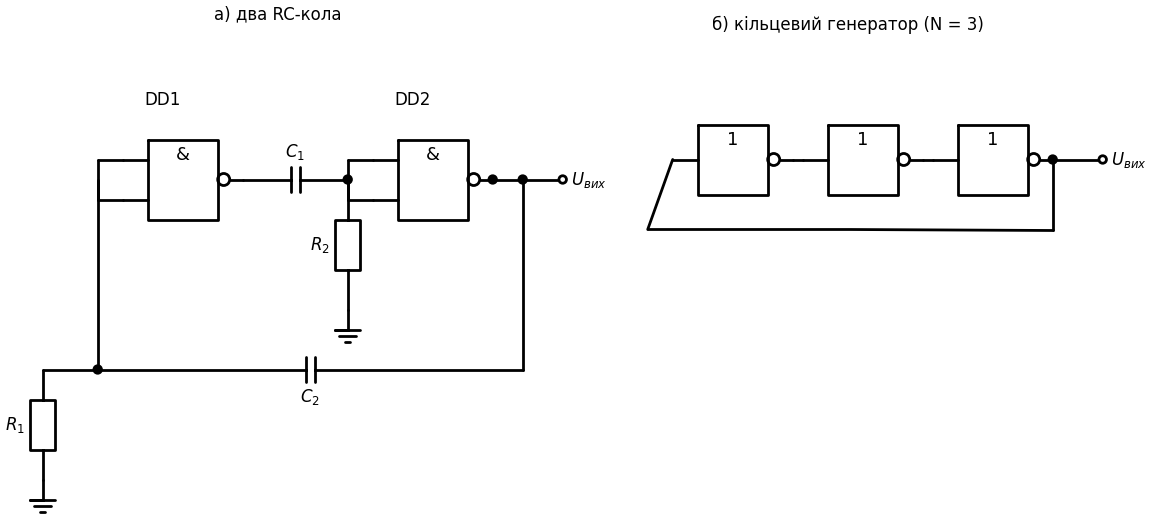

In [6]:
# а) мультивібратор на двох елементах з двома RC-колами; б) кільцевий генератор
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += elm.Label().at((4.0, 4.8)).label('а) два RC-кола')
        d += (g1 := Gate('&', 2).at((1.0, 2.0)).anchor('in1')); d += elm.Label().at((1.7, 3.1)).label('DD1')
        d += W((0.5, g1.in1[1]), (0.5, g1.in2[1])); d += W((0.5, g1.in1[1]), g1.in1); d += W((0.5, g1.in2[1]), g1.in2)
        d += (g2 := Gate('&', 2).at((6.0, 2.0)).anchor('in1')); d += elm.Label().at((6.7, 3.1)).label('DD2')
        d += W((5.5, g2.in1[1]), (5.5, g2.in2[1])); d += W((5.5, g2.in1[1]), g2.in1); d += W((5.5, g2.in2[1]), g2.in2)
        yc = (g1.in1[1] + g1.in2[1]) / 2
        d += elm.Capacitor().at(g1.out).to((5.5, g1.out[1])).label('$C_1$'); d += elm.Dot().at((5.5, g1.out[1]))
        d += elm.Dot().at((g2.out[0], g2.out[1])); d += W(g2.out, (g2.out[0] + 1.4, g2.out[1])); d += elm.Dot(open=True).at((g2.out[0] + 1.4, g2.out[1])).label('$U_{вих}$', loc='right')
        d += elm.Resistor().at((5.5, yc)).to((5.5, -1.0)).label('$R_2$', loc='top')
        d += elm.Ground().at((5.5, -1.0))
        d += W((g2.out[0] + 0.6, g2.out[1]), (g2.out[0] + 0.6, -2.2)); d += elm.Dot().at((g2.out[0] + 0.6, g2.out[1]))
        d += elm.Capacitor().at((g2.out[0] + 0.6, -2.2)).to((0.5, -2.2)).label('$C_2$', loc='bottom'); d += W((0.5, -2.2), (0.5, yc)); d += elm.Dot().at((0.5, -2.2))
        d += W((0.5, -2.2), (-0.6, -2.2))
        d += elm.Resistor().at((-0.6, -2.2)).to((-0.6, -4.4)).label('$R_1$', loc='top'); d += elm.Ground().at((-0.6, -4.4))
        # б) кільцевий генератор
        ox = 12
        d += elm.Label().at((ox + 3.4, 4.8)).label('б) кільцевий генератор (N = 3)')
        prev = None
        for k in range(3):
            d += (g := Gate('1', 1).at((ox + 2.6 * k, 2.0)).anchor('in1'))
            if prev is not None:
                d += W(prev.out, g.in1)
            if k == 0:
                first = g
            prev = g
        d += elm.Dot().at(prev.out); d += W(prev.out, (prev.out[0] + 1.0, 2.0)); d += elm.Dot(open=True).at((prev.out[0] + 1.0, 2.0)).label('$U_{вих}$', loc='right')
        d += W(prev.out, (prev.out[0], 0.6)); d += W((prev.out[0], 0.6), (ox - 0.5, 0.6)); d += W((ox - 0.5, 0.6), first.in1)

---

## Мультивібратори на логічних елементах з одним частотозадавальним колом <a class="anchor" id="one-rc"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 3.16</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати роботу мультивібратора на двох інверторах з одним RC-колом
> - Розраховувати період генерації
> - Пояснювати роботу мультивібратора на одному тригері Шмітта

</div>

### Мультивібратор на двох КМОН-інверторах з одним RC-колом

Два інвертори DD1, DD2 послідовно; конденсатор $C$ — з виходу DD2 на вузол $x$, резистор $R$ — з виходу DD1 на той самий вузол; вузол $x$ через захисний резистор $R_з$ ($\approx 10R$) з'єднано з входом DD1.

**Робота.** Нехай вихід DD2 = 1 ($E_ж$), DD1 = 0. Стрибок на виході DD2 через $C$ підняв вузол $x$ до $\approx E_ж + E_ж/2$; далі $C$ розряджається через $R$ на нульовий вихід DD1, напруга $u_x$ експоненційно спадає. Коли вона досягає порогу $U_{пор} \approx E_ж/2$, DD1 перемикається в 1, DD2 — у 0; стрибок $-E_ж$ через $C$ кидає $u_x$ до $\approx -E_ж/2$, і перезаряд іде до $E_ж$ через $R$… Кожен напівперіод — перезаряд з $\pm1{,}5E_ж$ відносно рушійної напруги до порогу:
$$t_{1,2} = RC\ln\frac{E_ж + U_{пор}}{U_{пор}} = RC\ln3\;\;(U_{пор} = E_ж/2),\qquad T = 2RC\ln3 \approx 2{,}2RC .$$
Захисний резистор $R_з$ обмежує струм вхідних захисних діодів КМОН-елемента при виході $u_x$ за межі $0\ldots E_ж$ (без нього діоди «зрізають» стрибки, і період зменшується до $\approx 1{,}4RC$).

### Мультивібратор на одному тригері Шмітта (інверторі 74HC14)

Резистор $R$ з виходу на вхід, конденсатор $C$ з входу на землю. Конденсатор перезаряджається між порогами $U_{пор}^+$ і $U_{пор}^-$:
$$T = RC\left[\ln\frac{E_ж - U_{пор}^-}{E_ж - U_{пор}^+} + \ln\frac{U_{пор}^+}{U_{пор}^-}\right].$$
Найпростіший генератор: один елемент, два компоненти. Застосування — тактові генератори простих пристроїв, генератори для «пищалок», зарядових насосів, світлодіодних мигалок.

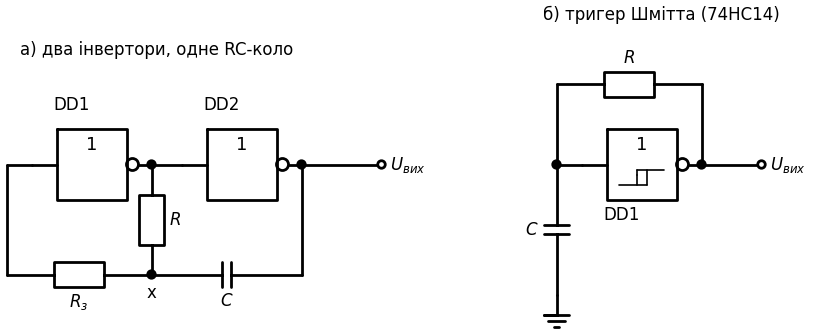

In [7]:
# а) мультивібратор на двох інверторах з одним RC-колом; б) на одному тригері Шмітта
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += elm.Label().at((3.4, 4.2)).label('а) два інвертори, одне RC-коло')
        d += (g1 := Gate('1', 1).at((1.0, 2.0)).anchor('in1')); d += elm.Label().at((1.7, 3.1)).label('DD1')
        d += (g2 := Gate('1', 1).at((4.0, 2.0)).anchor('in1')); d += elm.Label().at((4.7, 3.1)).label('DD2')
        d += W(g1.out, g2.in1); d += elm.Dot().at((3.4, 2.0))
        d += elm.Dot().at(g2.out); d += W(g2.out, (g2.out[0] + 1.6, 2.0)); d += elm.Dot(open=True).at((g2.out[0] + 1.6, 2.0)).label('$U_{вих}$', loc='right')
        d += W(g2.out, (g2.out[0], -0.2)); d += elm.Capacitor().at((g2.out[0], -0.2)).to((3.4, -0.2)).label('$C$', loc='bottom')
        d += elm.Dot().at((3.4, -0.2)).label('x', loc='bottom')
        d += elm.Resistor().at((3.4, 2.0)).to((3.4, -0.2)).label('$R$', loc='bottom')
        d += elm.Resistor().at((3.4, -0.2)).to((0.5, -0.2)).label('$R_з$', loc='bottom'); d += W((0.5, -0.2), (0.5, 2.0)); d += W((0.5, 2.0), g1.in1)
        # б) тригер Шмітта
        ox = 11
        d += elm.Label().at((ox + 2.5, 4.9)).label('б) тригер Шмітта (74HC14)')
        d += (g := Gate('1', 1).at((ox + 1.0, 2.0)).anchor('in1')); d += elm.Label().at((ox + 1.7, 0.9)).label('DD1')
        cx, cy = g.center                                    # умовний знак гістерезису всередині елемента
        for p1, p2 in [((-0.45, -0.25), (0.1, -0.25)), ((0.1, -0.25), (0.1, 0.05)), ((-0.1, -0.05), (-0.1, 0.05)),
                       ((-0.1, 0.05), (0.45, 0.05)), ((-0.1, -0.25), (-0.1, -0.05)), ((0.1, 0.05), (0.1, 0.05))]:
            d += elm.Line().at((cx + p1[0], cy + p1[1] - 0.15)).to((cx + p2[0], cy + p2[1] - 0.15)).linewidth(1.2)
        d += elm.Dot().at(g.out); d += W(g.out, (g.out[0] + 1.2, 2.0)); d += elm.Dot(open=True).at((g.out[0] + 1.2, 2.0)).label('$U_{вих}$', loc='right')
        d += W(g.out, (g.out[0], 3.6)); d += elm.Resistor().at((g.out[0], 3.6)).to((ox + 0.5, 3.6)).label('$R$'); d += W((ox + 0.5, 3.6), (ox + 0.5, 2.0))
        d += W((ox + 0.5, 2.0), g.in1); d += elm.Dot().at((ox + 0.5, 2.0))
        d += elm.Capacitor().at((ox + 0.5, 2.0)).to((ox + 0.5, -0.6)).label('$C$', loc='top'); d += elm.Ground().at((ox + 0.5, -0.6))

---
### 🔬 Інтерактивно: мультивібратор на двох КМОН-інверторах (PySpice) <a class="anchor" id="cmos-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Інвертори побудовано з n- і p-канальних МДН-транзисторів (модель рівня 1, поріг ≈ $E_ж/2$), $E_ж = 5$ В, $R_з = 10R$. Генерація починається після ввімкнення живлення. Порівняйте період з формулою $2RC\ln3$ і зверніть увагу на напругу у вузлі $x$: вона виходить за межі живлення до $\approx -E_ж/2$ і $1{,}5E_ж$.

</div>

In [8]:
# Мультивібратор на двох КМОН-інверторах з одним RC-колом
def cmos_astable(R_k=10.0, C_nF=10.0):

    def cmos_models(c, vdd=5.0):
        """КМОН-інвертори (як у CD4069 / 74HC04): n- і p-канальні МДН-транзистори рівня 1."""
        c.model('NM', 'NMOS', LEVEL=1, VTO=1.0, KP=200e-6, LAMBDA=0.02)
        c.model('PM', 'PMOS', LEVEL=1, VTO=-1.0, KP=200e-6, LAMBDA=0.02)
        # «увімкнення живлення» з плавним фронтом: виводить схему зі стану метастабільної рівноваги
        c.PulseVoltageSource('dd', 'vdd', c.gnd, initial_value=0, pulsed_value=vdd, rise_time=1e-6, fall_time=1e-6, pulse_width=10, period=20)
    def inverter(c, name, inp, out, wp=10e-6):
        c.MOSFET(name + 'n', out, inp, c.gnd, c.gnd, model='NM', l=1e-6, w=10e-6)
        c.MOSFET(name + 'p', out, inp, 'vdd', 'vdd', model='PM', l=1e-6, w=wp)

    R, C = R_k * 1e3, C_nF * 1e-9
    c = Circuit('CMOS astable'); cmos_models(c)
    inverter(c, '1', 'a', 'b'); inverter(c, '2', 'b', 'o', wp=14e-6)     # невелика асиметрія, як у реальних елементах
    c.C(1, 'o', 'x', C); c.R(1, 'x', 'b', R); c.R('z', 'x', 'a', 10 * R); c.C('in', 'a', c.gnd, 2e-12)   # вхідна ємність DD1
    T0 = 2 * R * C * np.log(3)
    t, v = tran(c, T0 / 500, 6 * T0)
    u = v['o']; e = t[1:][(u[1:] > 2.5) & (u[:-1] <= 2.5)]
    T = np.diff(e)[-2:].mean() if len(e) > 3 else np.nan
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(t * 1e3, v['o'], color='#F44336', label='вихід DD2'); ax.plot(t * 1e3, v['x'], color='#2196F3', label='вузол x')
    ax.axhline(2.5, color='k', ls=':', lw=1, label='поріг $E_ж/2$')
    ax.set_xlabel('t, мс'); ax.set_ylabel('В'); ax.legend(loc='upper right', fontsize=9)
    ax.set_title(f'T = {T*1e3:.3f} мс;  формула 2RC·ln3 = {T0*1e3:.3f} мс')
    plt.tight_layout(); plt.show()

interact(cmos_astable,
         R_k=widgets.FloatSlider(min=2, max=50, step=1, value=10, description='R (кОм)'),
         C_nF=widgets.FloatSlider(min=1, max=50, step=1, value=10, description='C (нФ)'));

interactive(children=(FloatSlider(value=10.0, description='R (кОм)', max=50.0, min=2.0, step=1.0), FloatSlider…

---

## Мультивібратор на інтегральному таймері 555 <a class="anchor" id="timer-555"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 3.17</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Знати структуру таймера 555: компаратори, RS-тригер, розрядний транзистор, дільник порогів
> - Пояснювати роботу таймера в автоколивальному режимі
> - Розраховувати тривалості імпульсу і паузи, частоту і шпаруватість

</div>

**Інтегральний таймер NE555** містить: резистивний дільник $3\times5$ кОм, що задає пороги $\frac23E_ж$ і $\frac13E_ж$; **два компаратори** — верхній (вхід THR, вивід 6) і нижній (вхід TRG, вивід 2); **RS-тригер**; **вихідний каскад** (вивід 3, струм до 200 мА); **розрядний транзистор** (вивід DIS 7), відкритий, коли вихід = 0; вхід скидання RST (4) і вхід керування порогом CTL (5).

**Автоколивальний режим.** Конденсатор $C$ заряджається від $E_ж$ через $R_A + R_B$ і розряджається через $R_B$ у розрядний транзистор; виводи THR і TRG з'єднані з конденсатором, тож $u_C$ коливається між $\frac13E_ж$ і $\frac23E_ж$:
- поки $u_C$ зростає від $\frac13$ до $\frac23E_ж$ — вихід = 1 (імпульс):
$$t_і = (R_A + R_B)C\ln2 \approx 0{,}693(R_A + R_B)C;$$
- коли $u_C = \frac23E_ж$, верхній компаратор скидає тригер: вихід = 0, розрядний транзистор відкривається, $C$ розряджається через $R_B$ до $\frac13E_ж$:
$$t_п = R_BC\ln2 \approx 0{,}693R_BC .$$
$$T = 0{,}693(R_A + 2R_B)C,\qquad f = \frac{1{,}44}{(R_A + 2R_B)C},\qquad D = \frac{R_A + R_B}{R_A + 2R_B} > 50\%.$$
Частота **не залежить від напруги живлення** (обидва пороги пропорційні $E_ж$) — стабільність $\sim 0{,}1\%/В$, $50\cdot10^{-6}/°C$.

**Шпаруватість $\le 50\%$:** діод паралельно $R_B$ (заряд через $R_A$ і діод, розряд — через $R_B$): $t_і \approx 0{,}693R_AC$, $t_п = 0{,}693R_BC$, при $R_A = R_B$ — меандр. Напруга на CTL зсуває пороги — **частотна модуляція / ГКН**.

**Застосування:** тактові генератори, ШІМ для двигунів і світлодіодів, генератори звуку, перетворювачі напруги (зарядові насоси), сигналізатори, генератори з керуванням напругою.

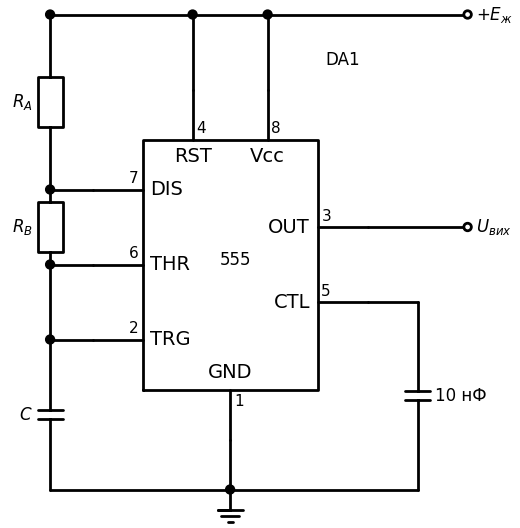

In [9]:
# Таймер 555 в автоколивальному режимі
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += (t := elm.Ic555().at((4, 0)).anchor('GND'))
        d += elm.Label().at((t.OUT[0] - 0.6, t.Vcc[1] + 0.5)).label('DA1')
        top = t.Vcc[1] + 1.5
        d += W(t.Vcc, (t.Vcc[0], top)); d += W(t.RST, (t.RST[0], top)); d += W((0.4, top), (t.OUT[0] + 2.0, top)); d += elm.Dot().at((t.Vcc[0], top))
        d += elm.Dot().at((t.RST[0], top)); d += elm.Dot(open=True).at((t.OUT[0] + 2.0, top)).label('$+E_ж$', loc='right')
        d += elm.Dot().at((0.4, top))
        d += elm.Resistor().at((0.4, top)).to((0.4, t.DIS[1])).label('$R_A$', loc='top'); d += W((0.4, t.DIS[1]), t.DIS); d += elm.Dot().at((0.4, t.DIS[1]))
        d += elm.Resistor().at((0.4, t.DIS[1])).to((0.4, t.THR[1])).label('$R_B$', loc='top'); d += W((0.4, t.THR[1]), t.THR); d += elm.Dot().at((0.4, t.THR[1]))
        d += W((0.4, t.THR[1]), (0.4, t.TRG[1])); d += W((0.4, t.TRG[1]), t.TRG); d += elm.Dot().at((0.4, t.TRG[1]))
        d += elm.Capacitor().at((0.4, t.TRG[1])).to((0.4, t.GND[1] - 1.0)).label('$C$', loc='top')
        d += W((0.4, t.GND[1] - 1.0), (t.CTL[0] + 1.0, t.GND[1] - 1.0)); d += W(t.GND, (t.GND[0], t.GND[1] - 1.0)); d += elm.Dot().at((t.GND[0], t.GND[1] - 1.0))
        d += elm.Ground().at((t.GND[0], t.GND[1] - 1.0))
        d += W(t.CTL, (t.CTL[0] + 1.0, t.CTL[1])); d += elm.Capacitor().at((t.CTL[0] + 1.0, t.CTL[1])).to((t.CTL[0] + 1.0, t.GND[1] - 1.0)).label('10 нФ', loc='bottom')
        d += W(t.OUT, (t.OUT[0] + 2.0, t.OUT[1])); d += elm.Dot(open=True).at((t.OUT[0] + 2.0, t.OUT[1])).label('$U_{вих}$', loc='right')

---
### 🔬 Інтерактивно: мультивібратор на таймері 555 (PySpice, модель біполярного 555) <a class="anchor" id="ne555-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Транзисторна модель таймера 555, $E_ж = 5$ В. Змінюйте $R_A$, $R_B$, $C$: напруга на конденсаторі коливається між $\frac13E_ж$ і $\frac23E_ж$, тривалості імпульсу і паузи відповідають формулам $0{,}693(R_A + R_B)C$ і $0{,}693R_BC$.

</div>

In [10]:
# Таймер 555 в автоколивальному режимі (модель BIP-555)
def ne555(RA_k=10.0, RB_k=10.0, C_nF=10.0):
    RA, RB, C = RA_k * 1e3, RB_k * 1e3, C_nF * 1e-9
    c = Circuit('555 astable'); c.include(spice_model('BIP-555.lib'))
    c.V(1, 'vcc', c.gnd, 5)
    c.X(1, '555bip', 'vcc', c.gnd, 'thr', 'vcc', 'ctl', 'dis', 'out', 'thr')     # THR і TRG з'єднані
    c.R('a', 'vcc', 'dis', RA); c.R('b', 'dis', 'thr', RB); c.C(1, 'thr', c.gnd, C); c.C(2, 'ctl', c.gnd, 10e-9)
    T0 = 0.693 * (RA + 2 * RB) * C
    t, v = tran(c, T0 / 400, 6 * T0)
    u = v['out']; up = t[1:][(u[1:] > 2.5) & (u[:-1] <= 2.5)]; dn = t[1:][(u[1:] < 2.5) & (u[:-1] >= 2.5)]
    T = np.diff(up)[-2:].mean() if len(up) > 3 else np.nan
    ti = (dn[dn > up[-2]][0] - up[-2]) if len(up) > 2 and np.any(dn > up[-2]) else np.nan
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(t * 1e3, v['out'], color='#F44336', label='вихід (вивід 3)'); ax.plot(t * 1e3, v['thr'], color='#2196F3', label='$u_C$ (виводи 2, 6)')
    for k in (1 / 3, 2 / 3):
        ax.axhline(5 * k, color='k', ls=':', lw=1)
    ax.set_xlabel('t, мс'); ax.set_ylabel('В'); ax.legend(loc='upper right', fontsize=9)
    ax.set_title(f'T = {T*1e3:.3f} мс (формула {T0*1e3:.3f}),  tі = {ti*1e3:.3f} мс (формула {0.693*(RA+RB)*C*1e3:.3f})')
    plt.tight_layout(); plt.show()

interact(ne555,
         RA_k=widgets.FloatSlider(min=1, max=100, step=1, value=10, description='RA (кОм)'),
         RB_k=widgets.FloatSlider(min=1, max=100, step=1, value=10, description='RB (кОм)'),
         C_nF=widgets.FloatSlider(min=1, max=100, step=1, value=10, description='C (нФ)'));

interactive(children=(FloatSlider(value=10.0, description='RA (кОм)', min=1.0, step=1.0), FloatSlider(value=10…

### ⚠️ Типова помилка

<div style="background-color: #fef2f2; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #dc2626; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

**Формула $T = 2RC\ln(1 + 2R_1/R_2)$ не враховує швидкість наростання і зміщення ОП.** На частотах у кілька кілогерц μA741 витрачає на кожне перемикання десятки мікросекунд, і реальний період помітно більший (див. моделювання з малою $C$). Аналогічно, період логічних мультивібраторів залежить від порогу елемента ($\pm10\%$ між партіями і з напругою живлення), а в таймера 555 — ні, бо пороги задані дільником від того самого живлення.

</div>

---
### ⚡ Практичне застосування: мультивібратори

<div style="background-color: #fffbeb; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #f59e0b; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Пристрій | Схема |
|---|---|
| Функціональний генератор (меандр + трикутник), ШІМ-модулятор | тригер Шмітта + інтегратор на ОП, компаратор |
| Тактовий генератор простого цифрового пристрою | КМОН-інвертори з RC або 74HC14 |
| Мигалка, звуковий сигналізатор, ШІМ для світлодіодів | таймер 555 |
| Зарядовий насос (подвоювач напруги) | 555 або 74HC14 + діоди і конденсатори |
| ГКН для ФАПЧ | кільцевий генератор / емітерно-зв'язаний мультивібратор |
| Перетворювач напруга–частота | інтегратор + компаратор + ключ скидання |

</div>

---
### ✅ Питання для самоперевірки: мультивібратори

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Як працює мультивібратор на ОП?</summary>

> **Відповідь:** Інвертувальний тригер Шмітта перезаряджає конденсатор через $R$ між порогами $\pm\gamma U_{нас}$; при досягненні порогу вихід перемикається. $T = 2RC\ln(1 + 2R_1/R_2)$.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Як змінити шпаруватість, не змінюючи період?</summary>

> **Відповідь:** Розділити коло перезаряду на дві гілки з діодами і потенціометром: $R' + R'' = $ const, $D = R'/(R' + R'')$.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Чому у мультивібраторі на двох КМОН-інверторах $T \approx 2{,}2RC$?</summary>

> **Відповідь:** Кожен напівперіод — перезаряд від $\pm1{,}5E_ж$ до порогу $E_ж/2$: $t = RC\ln3$.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Між якими рівнями коливається напруга на конденсаторі таймера 555?</summary>

> **Відповідь:** Між $E_ж/3$ і $2E_ж/3$, які задає внутрішній дільник; $t_і = 0{,}693(R_A+R_B)C$, $t_п = 0{,}693R_BC$.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Чому частота 555 майже не залежить від напруги живлення?</summary>

> **Відповідь:** І рушійна напруга, і пороги пропорційні $E_ж$, тож відношення в логарифмі стале.

</details>

---
### 📝 Задачі для самостійного розв'язання: мультивібратори


<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 1.** Мультивібратор на ОП: $R = 47$ кОм, $C = 10$ нФ, $R_1 = R_2$. Знайдіть частоту.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $T = 2\cdot47\cdot10^3\cdot10^{-8}\ln3 = 1{,}03$ мс; $f \approx 968$ Гц.

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 2.** Таймер 555: потрібна частота 1 кГц з $D = 60\%$, $C = 100$ нФ. Знайдіть $R_A$, $R_B$.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $(R_A + 2R_B)C = 1{,}443$ мс $\Rightarrow R_A + 2R_B = 14{,}43$ кОм; $D = (R_A + R_B)/(R_A + 2R_B) = 0{,}6 \Rightarrow R_B = 5{,}77$ кОм, $R_A = 2{,}89$ кОм.

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 3.** Мультивібратор на двох КМОН-інверторах має працювати на 10 кГц з $C = 1$ нФ. Знайдіть $R$ і $R_з$.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $R = 1/(2{,}2\cdot10^4\cdot10^{-9}) \approx 45$ кОм (стандарт 47 кОм); $R_з \approx 470$ кОм.

</details>

---

### 📌 Підсумок теми <a class="anchor" id="topic-summary"></a>

<div style="background-color: #f0fdf4; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #16a34a; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Мультивібратор | Період |
|---|---|
| На ОП (тригер Шмітта + RC) | $T = 2RC\ln(1 + 2R_1/R_2)$ |
| Функціональний генератор | $T = 4RCR_1/R_2$, трикутник $\pm U_{нас}R_1/R_2$ |
| З регульованою шпаруватістю | $t_{і,п} = R',R''\cdot C\ln(1 + 2R_1/R_2)$ |
| Два RC-кола на логіці | $t_{1,2} \approx 0{,}7R_{1,2}C_{1,2}$ (КМОН) |
| Два інвертори, одне RC | $T = 2RC\ln3 \approx 2{,}2RC$ |
| Тригер Шмітта 74HC14 | $T = RC\ln\frac{(E - U^-)U^+}{(E - U^+)U^-}$ |
| Таймер 555 | $t_і = 0{,}693(R_A+R_B)C$, $t_п = 0{,}693R_BC$, $f = 1{,}44/((R_A+2R_B)C)$ |

**Головні висновки.** Будь-який мультивібратор — це пороговий елемент з гістерезисом (тригер Шмітта, пара інверторів з ПЗЗ, компаратори таймера) плюс RC-коло, що перезаряджається між порогами. Період визначається сталою часу $RC$ і відношенням порогів до рушійної напруги; шпаруватість змінюють різними колами заряду і розряду або зсувом порогів.

</div>

---

## 📚 Рекомендована література та ресурси <a class="anchor" id="references"></a>

**Основна література**

1. Гусев В. Г., Гусев Ю. М. Електроніка і мікропроцесорна техніка. — К.: Вища школа (укр. пер.).
2. Опадчий Ю. Ф., Глудкин О. П., Гуров А. И. Аналоговая и цифровая электроника. — М.: Горячая линия – Телеком, 2000.
3. Титце У., Шенк К. Полупроводниковая схемотехника. — 12-е изд. — М.: ДМК Пресс, 2008.
4. Хоровиц П., Хилл У. Искусство схемотехники. — М.: Мир / Horowitz P., Hill W. The Art of Electronics. — 3rd ed. — Cambridge University Press, 2015.
5. Sedra A. S., Smith K. C. Microelectronic Circuits. — 8th ed. — Oxford University Press, 2020.

**Додаткова література**

6. Camenzind H. Designing Analog Chips. — Virtualbookworm, 2005 (історія і схемотехніка таймера 555).
7. Lancaster D. CMOS Cookbook. — 2nd ed. — Newnes, 1997.

**Програмні інструменти, що використовуються в конспекті**

- [PySpice](https://pyspice.fabrice-salvaire.fr/) + [ngspice](https://ngspice.sourceforge.io/) — схемотехнічне моделювання
- [SchemDraw](https://schemdraw.readthedocs.io/) — побудова електричних схем
- [SymPy](https://docs.sympy.org/) — символьні обчислення
- [NumPy](https://numpy.org/doc/) / [SciPy](https://docs.scipy.org/doc/scipy/) / [Matplotlib](https://matplotlib.org/) — чисельні розрахунки та графіки

---

<p style="text-align: center;">⬅️ [Тема 12. Генератори гармонійних коливань](Тема_12_Генератори_гармонійних_коливань.ipynb) &nbsp;|&nbsp; [Тема 14. Одновібратори](Тема_14_Одновібратори.ipynb) ➡️</p>

*Конспект підготовлено: Пахалюк Богдан Петрович, НУ "Чернігівська політехніка"*